In [32]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

In [33]:
real_news = pd.read_csv("True.csv")
fake_news = pd.read_csv("Fake.csv")

In [34]:
real_news["Category"] = "Real News"
fake_news["Category"] = "Fake News"

In [35]:
news = pd.concat([real_news, fake_news], ignore_index=True)

In [36]:
news["title"] = news["title"].fillna("")
news["text"] = news["text"].fillna("")


In [37]:
news["news_text"] = (news["title"] + " " + news["text"]).str.strip()

In [38]:
news = news[news["news_text"] != ""].copy()

In [39]:
news[["Category", "news_text"]].head()

,Category,news_text
0,Real News,"As U.S. budget fight looms, Republicans flip t..."
1,Real News,U.S. military to accept transgender recruits o...
2,Real News,Senior U.S. Republican senator: 'Let Mr. Muell...
3,Real News,FBI Russia probe helped by Australian diplomat...
4,Real News,Trump wants Postal Service to charge 'much mor...


In [40]:
# calculate linguistic features
news["word_count"] = news["news_text"].str.findall(r"\b\w+\b").str.len()

news["sentence_count"] = news["news_text"].str.count(r"[.!?]+").clip(lower=1)

news["average_sentence_length"] = (news["word_count"] / news["sentence_count"])

news[["Category", "word_count","sentence_count", "average_sentence_length"]].head()

,Category,word_count,sentence_count,average_sentence_length
0,Real News,775,45,17.222222
1,Real News,650,39,16.666667
2,Real News,477,25,19.080000
3,Real News,399,21,19.000000
4,Real News,892,60,14.866667


In [41]:
# measure vocabulary diversity
news["unique_word_count"] = news["news_text"].str.lower().str.findall(r"\b[a-z]+\b").apply(lambda words: len(set(words)))

news["vocabulary_diversity"] = (news["unique_word_count"]/ news["word_count"].replace(0, 1))

news[["Category", "unique_word_count", "vocabulary_diversity"]].head()

,Category,unique_word_count,vocabulary_diversity
0,Real News,362,0.467097
1,Real News,301,0.463077
2,Real News,221,0.463312
3,Real News,213,0.533835
4,Real News,364,0.408072


In [42]:
# measure punctuation usage
news["exclamation_count"] = news["news_text"].str.count("!")

news["question_count"] = news["news_text"].str.count(r"\?")

news["comma_count"] = news["news_text"].str.count(",")

news["exclamations_per_100_words"] = (news["exclamation_count"] / news["word_count"].replace(0, 1) * 100)

news[["Category", "exclamation_count",
      "question_count", "comma_count",
      "exclamations_per_100_words"]].head()

,Category,exclamation_count,question_count,comma_count,exclamations_per_100_words
0,Real News,0,0,55,0.000000
1,Real News,0,0,29,0.000000
2,Real News,0,0,19,0.000000
3,Real News,0,0,23,0.000000
4,Real News,1,1,51,0.112108


In [43]:
# TF-IDF text features
vectorizer = TfidfVectorizer(stop_words="english", max_features=5000)

tfidf_matrix = vectorizer.fit_transform(news["news_text"])

print("Number of articles:", tfidf_matrix.shape[0])
print("Number of text features:", tfidf_matrix.shape[1])

Number of articles: 44898
Number of text features: 5000


In [44]:
# compare the writing profiles of real news and fake news
real_vectors = tfidf_matrix[news["Category"].eq("Real News").to_numpy()]

fake_vectors = tfidf_matrix[news["Category"].eq("Fake News").to_numpy()]

real_profile = np.asarray(real_vectors.mean(axis=0))
fake_profile = np.asarray(fake_vectors.mean(axis=0))

similarity = cosine_similarity(real_profile, fake_profile)[0, 0]

print("Real vs Fake writing-profile similarity:", round(float(similarity), 3))

Real vs Fake writing-profile similarity: 0.71


In [45]:
# Compare linguistic features by category
linguistic_comparison = news.groupby("Category").agg(
    Average_Word_Count=("word_count", "mean"),
    Average_Sentence_Length=("average_sentence_length", "mean"),
    Average_Vocabulary_Diversity=("vocabulary_diversity", "mean"),
    Average_Exclamations=("exclamations_per_100_words", "mean"),
    Average_Questions=("question_count", "mean")
)

linguistic_comparison.round(3)

,Average_Word_Count,Average_Sentence_Length,Average_Vocabulary_Diversity,Average_Exclamations,Average_Questions
Category,,,,,
Fake News,451.876,20.811,0.557,0.463,1.280
Real News,404.327,20.789,0.552,0.020,0.107


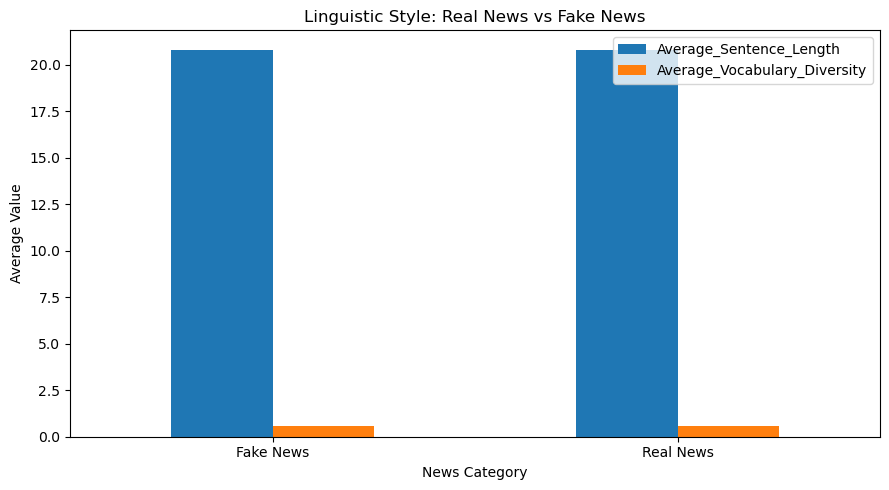

In [46]:
linguistic_comparison[["Average_Sentence_Length", "Average_Vocabulary_Diversity"]].plot(kind="bar", figsize=(9, 5))

plt.title("Linguistic Style: Real News vs Fake News")
plt.xlabel("News Category")
plt.ylabel("Average Value")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()